## 1. Đọc dữ liệu giao dịch

Mỗi dòng trong tệp CSV là một giao dịch; các mặt hàng trong dòng được phân tách bằng dấu phẩy. Đoạn mã kiểm tra số giao dịch và số mặt hàng để xác nhận đúng dữ liệu yêu cầu.


In [1]:
print("Lê Quốc Trung - 6451071082")

import csv
import io
import subprocess
import sys
import urllib.request
from pathlib import Path

EXPECTED_TRANSACTIONS = 9835
EXPECTED_ITEMS = 169
DRIVE_FILE_ID = "1UIeIAeGPrmXaSsFOtfhw9h5gK4RPkseI"
RAW_MIRROR_URL = "https://raw.githubusercontent.com/stedy/Machine-Learning-with-R-datasets/master/groceries.csv"


def parse_transactions(text):
    rows = csv.reader(io.StringIO(text))
    transactions = []
    for row in rows:
        items = [item.strip() for item in row if item and item.strip()]
        if items:
            transactions.append(sorted(set(items)))
    if transactions and len(transactions[0]) == 1 and transactions[0][0].strip().lower() in {
        "items", "item", "transaction", "transactions", "groceries"
    }:
        transactions = transactions[1:]
    return transactions


def matches_expected_data(candidate_transactions):
    unique_items = {item for transaction in candidate_transactions for item in transaction}
    return (
        len(candidate_transactions) == EXPECTED_TRANSACTIONS
        and len(unique_items) == EXPECTED_ITEMS
    )


transactions = None
source_description = None
local_candidates = [Path("groceries.csv"), Path("Groceries.csv"), Path("groceries - groceries.csv")]
local_file = next((path for path in local_candidates if path.is_file()), None)

if local_file is not None:
    try:
        local_text = local_file.read_text(encoding="utf-8-sig")
    except UnicodeDecodeError:
        local_text = local_file.read_text(encoding="latin-1")
    local_transactions = parse_transactions(local_text)
    if matches_expected_data(local_transactions):
        transactions = local_transactions
        source_description = str(local_file.resolve())

if transactions is None:
    drive_path = Path("groceries_from_drive.csv")
    try:
        try:
            import gdown
        except ImportError:
            subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "gdown"])
            import gdown
        gdown.download(id=DRIVE_FILE_ID, output=str(drive_path), quiet=True, fuzzy=True)
        drive_text = drive_path.read_text(encoding="utf-8-sig")
        drive_transactions = parse_transactions(drive_text)
        if matches_expected_data(drive_transactions):
            transactions = drive_transactions
            source_description = f"Google Drive ID {DRIVE_FILE_ID}"
        else:
            print("File Drive tải được nhưng không khớp kích thước kỳ vọng; sẽ dùng bản dự phòng.")
    except Exception as exc:
        print(f"Không đọc được file Drive ({exc}); sẽ dùng bản CSV dự phòng.")

if transactions is None:
    request = urllib.request.Request(RAW_MIRROR_URL, headers={"User-Agent": "Mozilla/5.0"})
    with urllib.request.urlopen(request, timeout=60) as response:
        mirror_text = response.read().decode("utf-8-sig")
    mirror_transactions = parse_transactions(mirror_text)
    if not matches_expected_data(mirror_transactions):
        raise ValueError(
            "Dữ liệu tải về không đúng kỳ vọng: cần 9.835 giao dịch và 169 mặt hàng, "
            f"nhận {len(mirror_transactions)} giao dịch / "
            f"{len({item for t in mirror_transactions for item in t})} mặt hàng."
        )
    transactions = mirror_transactions
    source_description = RAW_MIRROR_URL

print("Nguồn dữ liệu:", source_description)
print("Số giao dịch:", len(transactions))
print("Số mặt hàng duy nhất:", len({item for transaction in transactions for item in transaction}))
print("Số mặt hàng trong một giao dịch — min/trung vị/max:",
      min(map(len, transactions)),
      float(__import__("numpy").median(list(map(len, transactions)))),
      max(map(len, transactions)))
print("Một vài giao dịch đầu:")
for number, transaction in enumerate(transactions[:5], start=1):
    print(f"{number}: {transaction}")


Lê Quốc Trung - 6451071082
Nguồn dữ liệu: Google Drive ID 1UIeIAeGPrmXaSsFOtfhw9h5gK4RPkseI
Số giao dịch: 9835
Số mặt hàng duy nhất: 169
Số mặt hàng trong một giao dịch — min/trung vị/max: 1 3.0 32
Một vài giao dịch đầu:
1: ['citrus fruit', 'margarine', 'ready soups', 'semi-finished bread']
2: ['coffee', 'tropical fruit', 'yogurt']
3: ['whole milk']
4: ['cream cheese', 'meat spreads', 'pip fruit', 'yogurt']
5: ['condensed milk', 'long life bakery product', 'other vegetables', 'whole milk']


## 2. Mã hóa one-hot


In [2]:
print("Lê Quốc Trung - 6451071082")

import numpy as np
import pandas as pd
from IPython.display import display

try:
    from mlxtend.preprocessing import TransactionEncoder
except ImportError:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "mlxtend"])
    from mlxtend.preprocessing import TransactionEncoder

encoder = TransactionEncoder()
one_hot_array = encoder.fit(transactions).transform(transactions, sparse=False)
one_hot = pd.DataFrame(one_hot_array, columns=encoder.columns_, dtype=bool)

print("Kích thước ma trận one-hot:", one_hot.shape)
print("Số giá trị True:", int(one_hot.to_numpy().sum()))
print("Top 10 mặt hàng phổ biến nhất:")
display(one_hot.sum().sort_values(ascending=False).head(10).rename("transaction_count").to_frame())
display(one_hot.head())


Lê Quốc Trung - 6451071082
Kích thước ma trận one-hot: (9835, 169)
Số giá trị True: 43367
Top 10 mặt hàng phổ biến nhất:


,transaction_count
whole milk,2513
other vegetables,1903
rolls/buns,1809
soda,1715
yogurt,1372
bottled water,1087
root vegetables,1072
tropical fruit,1032
shopping bags,969
sausage,924


,Instant food products,UHT-milk,abrasive cleaner,artif. sweetener,baby cosmetics,baby food,bags,baking powder,bathroom cleaner,beef,...,turkey,vinegar,waffles,whipped/sour cream,whisky,white bread,white wine,whole milk,yogurt,zwieback
0,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
1,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,True,False
2,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,True,False,False
3,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,True,False
4,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,True,False,False


## 3. Các mức min_sup

Dùng các mức tỷ lệ  ,01,  ,02, ...,  ,10; khi trình bày, các mức này tương ứng 1%, 2%, ..., 10%. min_count là số giao dịch tối thiểu tương ứng sau khi làm tròn lên.


In [3]:
print("Lê Quốc Trung - 6451071082")

import math
import numpy as np
import pandas as pd
from pathlib import Path

support_levels = np.round(np.linspace(0.01, 0.10, 10), 2)
output_dir = Path("groceries_frequent_itemsets")
output_dir.mkdir(parents=True, exist_ok=True)

support_table = pd.DataFrame({
    "min_support_fraction": support_levels,
    "min_support_percent": support_levels * 100,
    "min_transaction_count": [math.ceil(level * len(transactions)) for level in support_levels],
})
display(support_table)


Lê Quốc Trung - 6451071082


,min_support_fraction,min_support_percent,min_transaction_count
0,0.01,1.0,99
1,0.02,2.0,197
2,0.03,3.0,296
3,0.04,4.0,394
4,0.05,5.0,492
5,0.06,6.0,591
6,0.07,7.0,689
7,0.08,8.0,787
8,0.09,9.0,886
9,0.10,10.0,984


## a) Tìm các tập phổ biến bằng Apriori và ghi nhận thời gian


In [7]:
print("Lê Quốc Trung - 6451071082")
import warnings
warnings.filterwarnings(
    "ignore",
    category=DeprecationWarning,
    module=r"jupyter_client\.session"
)
import gc
import time
from mlxtend.frequent_patterns import apriori


def save_frequent_itemsets(itemsets_df, algorithm_name, support_fraction):
    support_percent = support_fraction * 100
    tag = f"{support_percent:05.2f}".replace(".", "p")
    file_path = output_dir / f"{algorithm_name.lower()}_min_sup_{tag}pct.csv.gz"

    exported = pd.DataFrame({
        "min_support_fraction": support_fraction,
        "min_support_percent": support_percent,
        "support": itemsets_df["support"].to_numpy(),
        "itemset_size": itemsets_df["itemsets"].map(len).to_numpy(),
        "itemset": itemsets_df["itemsets"].map(lambda items: " | ".join(sorted(items))).to_numpy(),
    })
    exported.to_csv(file_path, index=False, compression="gzip")
    return file_path


apriori_records = []
for support_fraction in support_levels:
    started = time.perf_counter()
    frequent_itemsets = apriori(
        one_hot,
        min_support=float(support_fraction),
        use_colnames=True,
        low_memory=False,
    )
    elapsed = time.perf_counter() - started
    result_file = save_frequent_itemsets(frequent_itemsets, "apriori", float(support_fraction))
    record = {
        "algorithm": "Apriori",
        "min_support_fraction": float(support_fraction),
        "min_support_percent": float(support_fraction * 100),
        "min_transaction_count": math.ceil(float(support_fraction) * len(transactions)),
        "frequent_itemset_count": len(frequent_itemsets),
        "runtime_seconds": elapsed,
        "results_file": str(result_file),
    }
    apriori_records.append(record)
    print(
        f"min_sup={support_fraction:.2f} ({support_fraction:.0%}) | "
        f"itemsets={len(frequent_itemsets):,} | time={elapsed:.4f}s | file={result_file.name}"
    )
    del frequent_itemsets
    gc.collect()

apriori_summary = pd.DataFrame(apriori_records)


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

Lê Quốc Trung - 6451071082
min_sup=0.01 (1%) | itemsets=333 | time=1.7033s | file=apriori_min_sup_01p00pct.csv.gz
min_sup=0.02 (2%) | itemsets=122 | time=0.6822s | file=apriori_min_sup_02p00pct.csv.gz
min_sup=0.03 (3%) | itemsets=63 | time=0.2395s | file=apriori_min_sup_03p00pct.csv.gz
min_sup=0.04 (4%) | itemsets=41 | time=0.1698s | file=apriori_min_sup_04p00pct.csv.gz
min_sup=0.05 (5%) | itemsets=31 | time=0.0664s | file=apriori_min_sup_05p00pct.csv.gz
min_sup=0.06 (6%) | itemsets=21 | time=0.0313s | file=apriori_min_sup_06p00pct.csv.gz
min_sup=0.07 (7%) | itemsets=19 | time=0.0398s | file=apriori_min_sup_07p00pct.csv.gz
min_sup=0.08 (8%) | itemsets=13 | time=0.0225s | file=apriori_min_sup_08p00pct.csv.gz
min_sup=0.09 (9%) | itemsets=10 | time=0.0239s | file=apriori_min_sup_09p00pct.csv.gz
min_sup=0.10 (10%) | itemsets=8 | time=0.0257s | file=apriori_min_sup_10p00pct.csv.gz


## b) Tìm các tập phổ biến bằng FP-Growth và ghi nhận thời gian


In [8]:
print("Lê Quốc Trung - 6451071082")
import warnings
warnings.filterwarnings(
    "ignore",
    category=DeprecationWarning,
    module=r"jupyter_client\.session"
)
import gc
import time
from mlxtend.frequent_patterns import fpgrowth

fpgrowth_records = []
for support_fraction in support_levels:
    started = time.perf_counter()
    frequent_itemsets = fpgrowth(
        one_hot,
        min_support=float(support_fraction),
        use_colnames=True,
    )
    elapsed = time.perf_counter() - started
    result_file = save_frequent_itemsets(frequent_itemsets, "fpgrowth", float(support_fraction))
    record = {
        "algorithm": "FP-Growth",
        "min_support_fraction": float(support_fraction),
        "min_support_percent": float(support_fraction * 100),
        "min_transaction_count": math.ceil(float(support_fraction) * len(transactions)),
        "frequent_itemset_count": len(frequent_itemsets),
        "runtime_seconds": elapsed,
        "results_file": str(result_file),
    }
    fpgrowth_records.append(record)
    print(
        f"min_sup={support_fraction:.2f} ({support_fraction:.0%}) | "
        f"itemsets={len(frequent_itemsets):,} | time={elapsed:.4f}s | file={result_file.name}"
    )
    del frequent_itemsets
    gc.collect()

fpgrowth_summary = pd.DataFrame(fpgrowth_records)


Lê Quốc Trung - 6451071082
min_sup=0.01 (1%) | itemsets=333 | time=10.9970s | file=fpgrowth_min_sup_01p00pct.csv.gz
min_sup=0.02 (2%) | itemsets=122 | time=2.0232s | file=fpgrowth_min_sup_02p00pct.csv.gz
min_sup=0.03 (3%) | itemsets=63 | time=1.1994s | file=fpgrowth_min_sup_03p00pct.csv.gz
min_sup=0.04 (4%) | itemsets=41 | time=0.6954s | file=fpgrowth_min_sup_04p00pct.csv.gz
min_sup=0.05 (5%) | itemsets=31 | time=0.3551s | file=fpgrowth_min_sup_05p00pct.csv.gz
min_sup=0.06 (6%) | itemsets=21 | time=0.2207s | file=fpgrowth_min_sup_06p00pct.csv.gz
min_sup=0.07 (7%) | itemsets=19 | time=0.1961s | file=fpgrowth_min_sup_07p00pct.csv.gz
min_sup=0.08 (8%) | itemsets=13 | time=0.0945s | file=fpgrowth_min_sup_08p00pct.csv.gz
min_sup=0.09 (9%) | itemsets=10 | time=0.1223s | file=fpgrowth_min_sup_09p00pct.csv.gz
min_sup=0.10 (10%) | itemsets=8 | time=0.0886s | file=fpgrowth_min_sup_10p00pct.csv.gz


## c) Biểu đồ so sánh thời gian và nhận xét

Biểu đồ dưới đây so sánh thời gian chạy hai thuật toán tại cùng mức hỗ trợ. Mỗi thời gian chỉ tính lời gọi thuật toán; thời gian ghi các file kết quả được loại khỏi phép đo.

Thông thường khi hạ min_sup, số tập phổ biến và thời gian chạy tăng. Apriori tạo ứng viên và quét ma trận lặp lại theo từng kích thước tập; FP-Growth nén giao dịch thành cây FP để khai phá mẫu mà không sinh ứng viên theo cách Apriori. Thuật toán nhanh hơn trong kết quả cụ thể còn phụ thuộc dữ liệu, phiên bản thư viện và phần cứng.


Lê Quốc Trung - 6451071082


,min_support_percent,min_transaction_count,algorithm,frequent_itemset_count,runtime_seconds,results_file
0,1.0,99,Apriori,333,1.703288,groceries_frequent_itemsets/apriori_min_sup_01...
1,1.0,99,FP-Growth,333,10.997038,groceries_frequent_itemsets/fpgrowth_min_sup_0...
2,2.0,197,Apriori,122,0.682152,groceries_frequent_itemsets/apriori_min_sup_02...
3,2.0,197,FP-Growth,122,2.023233,groceries_frequent_itemsets/fpgrowth_min_sup_0...
4,3.0,296,Apriori,63,0.239504,groceries_frequent_itemsets/apriori_min_sup_03...
5,3.0,296,FP-Growth,63,1.199414,groceries_frequent_itemsets/fpgrowth_min_sup_0...
6,4.0,394,Apriori,41,0.169812,groceries_frequent_itemsets/apriori_min_sup_04...
7,4.0,394,FP-Growth,41,0.695444,groceries_frequent_itemsets/fpgrowth_min_sup_0...
8,5.0,492,Apriori,31,0.066417,groceries_frequent_itemsets/apriori_min_sup_05...
9,5.0,492,FP-Growth,31,0.355051,groceries_frequent_itemsets/fpgrowth_min_sup_0...


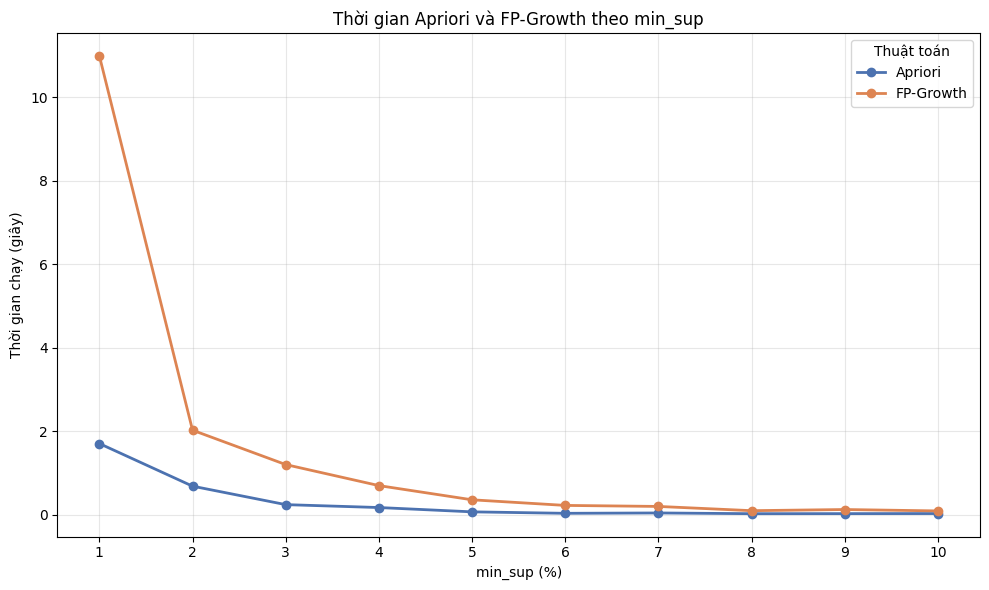

Nhanh nhất trong các lần chạy: Apriori tại min_sup=8% (0.0225 giây).
Thời gian trung bình theo thuật toán (giây):


,mean_runtime_seconds
algorithm,
Apriori,0.300435
FP-Growth,1.599247


Nhận xét: dựa vào biểu đồ và bảng trên, hãy so sánh tốc độ hai thuật toán; thời gian đo được có thể khác theo cấu hình môi trường.
Đã lưu bảng so sánh thời gian: /content/groceries_frequent_itemsets/runtime_comparison.csv


In [9]:
print("Lê Quốc Trung - 6451071082")
import warnings
warnings.filterwarnings(
    "ignore",
    category=DeprecationWarning,
    module=r"jupyter_client\.session"
)
import matplotlib.pyplot as plt

comparison = pd.concat([apriori_summary, fpgrowth_summary], ignore_index=True)
comparison = comparison.sort_values(["min_support_percent", "algorithm"]).reset_index(drop=True)
display(comparison[[
    "min_support_percent", "min_transaction_count", "algorithm",
    "frequent_itemset_count", "runtime_seconds", "results_file"
]])

fig, ax = plt.subplots(figsize=(10, 6))
colors = {"Apriori": "#4c72b0", "FP-Growth": "#dd8452"}
for algorithm_name, group in comparison.groupby("algorithm"):
    group = group.sort_values("min_support_percent")
    ax.plot(
        group["min_support_percent"],
        group["runtime_seconds"],
        marker="o",
        linewidth=2,
        label=algorithm_name,
        color=colors[algorithm_name],
    )
ax.set_title("Thời gian Apriori và FP-Growth theo min_sup")
ax.set_xlabel("min_sup (%)")
ax.set_ylabel("Thời gian chạy (giây)")
ax.set_xticks(support_levels * 100)
ax.grid(True, alpha=0.3)
ax.legend(title="Thuật toán")
plt.tight_layout()
plt.show()

fastest = comparison.loc[comparison["runtime_seconds"].idxmin()]
print(
    f"Nhanh nhất trong các lần chạy: {fastest['algorithm']} tại "
    f"min_sup={fastest['min_support_percent']:.0f}% "
    f"({fastest['runtime_seconds']:.4f} giây)."
)
mean_time = comparison.groupby("algorithm")["runtime_seconds"].mean().sort_values()
print("Thời gian trung bình theo thuật toán (giây):")
display(mean_time.rename("mean_runtime_seconds").to_frame())
print("Nhận xét: dựa vào biểu đồ và bảng trên, hãy so sánh tốc độ hai thuật toán; thời gian đo được có thể khác theo cấu hình môi trường.")

comparison.to_csv(output_dir / "runtime_comparison.csv", index=False)
print("Đã lưu bảng so sánh thời gian:", (output_dir / "runtime_comparison.csv").resolve())


## Kết luận

Đã thực hiện one-hot encoding, tìm và lưu toàn bộ frequent itemsets cho từng min_sup bằng cả Apriori và FP-Growth, đồng thời ghi nhận thời gian và vẽ biểu đồ so sánh. Các file .csv.gz trong thư mục groceries_frequent_itemsets chứa min_sup, support, kích thước và tên từng itemset;
untime_comparison.csv chứa số lượng itemset và thời gian.
